## Coffee Production, Export & Import: Cleaning and Analysis
### Part 1 – Load and Inspect the Datasets

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load each raw file into its own DataFrame (no cleaning yet)
production = pd.read_csv("Coffee_production.csv")
export = pd.read_csv("Coffee_export.csv")
imports = pd.read_csv("Coffee_import.csv")   # "import" is a reserved word in Python

frames = {"production": production, "export": export, "import": imports}

In [4]:
for name, df in frames.items():
    print(f"=== {name.upper()} ===")
    print("Shape:", df.shape)
    print(df.dtypes.value_counts().to_string(), "\n")
    print(df.dtypes.to_string(), "\n")

=== PRODUCTION ===
Shape: (55, 33)
float64    31
str         2 

Country                 str
Coffee type             str
1990/91             float64
1991/92             float64
1992/93             float64
1993/94             float64
1994/95             float64
1995/96             float64
1996/97             float64
1997/98             float64
1998/99             float64
1999/00             float64
2000/01             float64
2001/02             float64
2002/03             float64
2003/04             float64
2004/05             float64
2005/06             float64
2006/07             float64
2007/08             float64
2008/09             float64
2009/10             float64
2010/11             float64
2011/12             float64
2012/13             float64
2013/14             float64
2014/15             float64
2015/16             float64
2016/17             float64
2017/18             float64
2018/19             float64
2019/20             float64
Total_production    float64 

=== EXPOR

In [5]:
# repr() makes leading/trailing spaces visible
export_countries = sorted(export["Country"].unique())
import_countries = sorted(imports["Country"].unique())

print(f"EXPORT: {len(export_countries)} countries")
print([repr(c) for c in export_countries], "\n")
print(f"IMPORT: {len(import_countries)} countries")
print([repr(c) for c in import_countries], "\n")

# Do the two lists align perfectly?
print("Identical lists?", export_countries == import_countries)
print("In both:", sorted(set(export_countries) & set(import_countries)))
print("Export only:", len(set(export_countries) - set(import_countries)))
print("Import only:", len(set(import_countries) - set(export_countries)))

EXPORT: 55 countries
["'Angola'", "'Bolivia (Plurinational State of)'", "'Brazil'", "'Burundi'", "'Cameroon'", "'Central African Republic'", "'Colombia'", "'Congo'", "'Costa Rica'", "'Cuba'", '"Côte d\'Ivoire"', "'Democratic Republic of Congo'", "'Dominican Republic'", "'Ecuador'", "'El Salvador'", "'Equatorial Guinea'", "'Ethiopia'", "'Gabon'", "'Ghana'", "'Guatemala'", "'Guinea'", "'Guyana'", "'Haiti'", "'Honduras'", "'India'", "'Indonesia'", "'Jamaica'", "'Kenya'", '"Lao People\'s Democratic Republic"', "'Liberia'", "'Madagascar'", "'Malawi'", "'Mexico'", "'Nepal'", "'Nicaragua'", "'Nigeria'", "'Panama'", "'Papua New Guinea'", "'Paraguay'", "'Peru'", "'Philippines'", "'Rwanda'", "'Sierra Leone'", "'Sri Lanka'", "'Tanzania'", "'Thailand'", "'Timor-Leste'", "'Togo'", "'Trinidad & Tobago'", "'Uganda'", "'Venezuela'", "'Viet Nam'", "'Yemen'", "'Zambia'", "'Zimbabwe'"] 

IMPORT: 35 countries
["'   Austria'", "'   Belgium'", "'   Belgium/Luxembourg'", "'   Bulgaria'", "'   Croatia'", "'  

In [6]:
# --- Part 2: data quality checks ---

# 1. Null / missing values per DataFrame
for name, df in frames.items():
    nulls = df.isna().sum()
    print(f"{name.upper()} columns with nulls:", nulls[nulls > 0].to_dict() or "none")

# 2. Columns stored as text that should be numeric (object/str columns)
for name, df in frames.items():
    text_cols = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
    print(f"{name.upper()} text columns:", text_cols)

# 3. Impossible values: negative numbers
for name, df in frames.items():
    num = df.select_dtypes("number")
    neg = (num < 0).sum()
    print(f"{name.upper()} negative counts:", neg[neg > 0].to_dict() or "none")

# 4. Zeros that may mean "not reported" rather than "no coffee"
for name, df in frames.items():
    year_cols = [c for c in df.columns if c not in ("Country", "Coffee type") and not c.startswith("Total")]
    zeros = (df[year_cols] == 0).sum(axis=1)
    print(f"{name.upper()} rows with zeros:", dict(zip(df["Country"].str.strip()[zeros > 0], zeros[zeros > 0])))

# 5. Country names: whitespace, and matches between files
for name, df in frames.items():
    padded = (df["Country"] != df["Country"].str.strip()).sum()
    print(f"{name.upper()} names with extra whitespace:", padded)

prod_names = set(production["Country"].str.strip())
exp_names = set(export["Country"].str.strip())
imp_names = set(imports["Country"].str.strip())
print("Production vs export differences:", prod_names ^ exp_names or "none")
print("Export vs import overlap:", exp_names & imp_names or "none")

PRODUCTION columns with nulls: none
EXPORT columns with nulls: none
IMPORT columns with nulls: none
PRODUCTION text columns: ['Country', 'Coffee type']
EXPORT text columns: ['Country']
IMPORT text columns: ['Country']
PRODUCTION negative counts: none
EXPORT negative counts: {'2014': 1, '2015': 1, '2019': 1}
IMPORT negative counts: none
PRODUCTION rows with zeros: {'Timor-Leste': 10, 'Equatorial Guinea': 22, 'Gabon': 8, 'Guyana': 8, "Lao People's Democratic Republic": 8, 'Nepal': 13, 'Yemen': 8}
EXPORT rows with zeros: {'Congo': 23, 'Equatorial Guinea': 20, 'Gabon': 14, 'Guyana': 8, 'Liberia': 9, 'Nepal': 13, 'Paraguay': 11, 'Sri Lanka': 3, 'Timor-Leste': 10, 'Trinidad & Tobago': 2, 'Venezuela': 4}
IMPORT rows with zeros: {'Belgium': 9, 'Belgium/Luxembourg': 21, 'Croatia': 2, 'Estonia': 2, 'Latvia': 2, 'Lithuania': 2, 'Luxembourg': 9, 'Slovakia': 3, 'Slovenia': 2, 'Russian Federation': 2}
PRODUCTION names with extra whitespace: 0
EXPORT names with extra whitespace: 0
IMPORT names with e

In [7]:
year_cols = [c for c in export.columns if c.isdigit()]
neg = export.melt(id_vars="Country", value_vars=year_cols, var_name="Year", value_name="Value")
print(neg[neg["Value"] < 0])

     Country  Year       Value
1322  Brazil  2014 -2147483648
1377  Brazil  2015 -2147483648
1597  Brazil  2019 -2147483648


## Part 2 – Data Quality Assessment

**1. Missing values.** `isna()` found **no null cells** in any of the three files.
However, missing data is hidden in two other forms:
- **Sentinel values:** Brazil's exports for 2014, 2015 and 2019 are `-2,147,483,648`
  (the minimum 32-bit integer, a data-entry/overflow error). Coffee exports cannot be
  negative, so these are really missing values.
- **Zeros that mean "not reported":** Many rows contain runs of zeros, e.g. Belgium
  (9 zeros) and Belgium/Luxembourg (21 zeros) because the two were reported as one
  combined country until 1998; Croatia, Estonia, Latvia, Lithuania, Slovakia, Slovenia
  and Russia (2–3 zeros each) begin reporting in the early 1990s; Yemen, Laos and
  Timor-Leste in production start with zero years. These are reporting gaps, not true
  zero consumption or output.

**2. Numbers stored as text.** All year and total columns are already numeric
(`float64` in production, `int64` in export and import). Only `Country` (and
`Coffee type` in production) are text, and those should be. There are no commas or
spaces inside numbers in this copy. The cleaning step will still apply
`str.replace(",", "")`, `str.strip()` and `pd.to_numeric()` as a safeguard so the
pipeline works if a messier version of the file is used.

**3. Country name discrepancies.**
- **28 of the 35 import country names have leading spaces** (e.g. `'   Austria'`),
  so they would never match anything on a merge.
- Production and export contain exactly the same 55 countries after stripping.
- Export and import share **no countries**: exporters are producing nations and
  importers are consuming nations. A trade balance across files therefore needs
  a combined country list, with countries absent from a file treated as 0 for that flow.
- `Belgium/Luxembourg` (pre-1999) overlaps with separate `Belgium` and `Luxembourg`
  rows (1999+), which would double count if summed naively.
- Naming conventions vary (e.g. `Viet Nam`, `Côte d'Ivoire`, `Trinidad & Tobago`,
  `Bolivia (Plurinational State of)`); these match across production and export, so no
  renaming is needed between those two.

## Part 3 – Clean the Datasets
Each step below fixes one issue found in Part 2. I work on copies (`prod_c`, `exp_c`, `imp_c`)
so the raw DataFrames stay available for comparison.

### 3.1 Standardize country names
**Why:** Import names carry leading spaces, so they could never match another file. I strip
whitespace, collapse repeated spaces, and apply **one shared alias map to all three frames**
(e.g. "United States of America" → "United States", "Viet Nam" → "Vietnam"), so a country
has exactly one spelling everywhere. I also check for duplicates and trim `Coffee type`.

In [8]:
prod_c, exp_c, imp_c = production.copy(), export.copy(), imports.copy()

# One shared alias map, applied identically to all three files
NAME_MAP = {
    "Viet Nam": "Vietnam",
    "Lao People's Democratic Republic": "Laos",
    "Bolivia (Plurinational State of)": "Bolivia",
    "Côte d'Ivoire": "Ivory Coast",
    "Democratic Republic of Congo": "DR Congo",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "United States of America": "United States",
    "Russian Federation": "Russia",
}

def clean_names(s):
    s = s.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    return s.replace(NAME_MAP)

for df in (prod_c, exp_c, imp_c):
    df["Country"] = clean_names(df["Country"])
prod_c["Coffee type"] = prod_c["Coffee type"].astype(str).str.strip()

print("Production == Export countries:", set(prod_c["Country"]) == set(exp_c["Country"]))
print("Whitespace left:", sum((d["Country"] != d["Country"].str.strip()).sum() for d in (prod_c, exp_c, imp_c)))
print("Duplicate countries (prod, exp, imp):", [int(d["Country"].duplicated().sum()) for d in (prod_c, exp_c, imp_c)])

Production == Export countries: True
Whitespace left: 0
Duplicate countries (prod, exp, imp): [0, 0, 0]


### 3.2 Consistent year labels and numeric types
**Why:** Production uses crop-year labels (`1990/91`), export and import use `1990`. I rename
all to the starting year as an integer so the frames line up. Although Part 2 found no text
numbers in this copy, I still remove commas and spaces and call `pd.to_numeric()` on every
year and total column as a safeguard; `errors="coerce"` turns anything unparseable into NaN.

In [9]:
def year_label(col):
    return int(str(col)[:4])          # "1990/91" -> 1990, "1990" -> 1990

for df in (prod_c, exp_c, imp_c):
    df.rename(columns={c: year_label(c) for c in df.columns if str(c)[:4].isdigit()}, inplace=True)

YEARS = list(range(1990, 2020))

def to_numeric_safe(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(
            df[c].astype(str).str.replace(",", "", regex=False).str.strip(),
            errors="coerce")
    return df

for df, total in ((prod_c, "Total_production"), (exp_c, "Total_export"), (imp_c, "Total_import")):
    to_numeric_safe(df, YEARS + [total])

print(prod_c.dtypes.value_counts().to_dict())
print(exp_c.dtypes.value_counts().to_dict())
print(imp_c.dtypes.value_counts().to_dict())

{dtype('float64'): 31, <StringDtype(storage='python', na_value=nan)>: 2}
{dtype('int64'): 31, <StringDtype(storage='python', na_value=nan)>: 1}
{dtype('int64'): 31, <StringDtype(storage='python', na_value=nan)>: 1}


### 3.3 Impossible values: Brazil's negative exports
**Why:** Brazil's 2014, 2015 and 2019 exports are -2,147,483,648, the smallest 32-bit integer.
Exports cannot be negative, so I convert them to NaN. Rather than leaving gaps or using one
overall median (which would understate Brazil's recent, higher exports), I fill them by
**linear interpolation within Brazil's own time series**: 2014 and 2015 are estimated
between 2013 and 2016, and 2019 (no later value) carries forward 2018. I did not impute
other countries; only Brazil had these values.

In [10]:
# Show the bad values before changing anything
bad = exp_c.melt(id_vars="Country", value_vars=YEARS, var_name="Year", value_name="Value")
print(bad[bad["Value"] < 0])

# Negative volumes are impossible -> missing
for df in (prod_c, exp_c, imp_c):
    df[YEARS] = df[YEARS].mask(df[YEARS] < 0, np.nan)

# Fill gaps along each country's own timeline
exp_c[YEARS] = exp_c[YEARS].interpolate(axis=1, limit_direction="both")
print(exp_c.loc[exp_c["Country"] == "Brazil", [2013, 2014, 2015, 2016, 2018, 2019]])

     Country  Year       Value
1322  Brazil  2014 -2147483648
1377  Brazil  2015 -2147483648
1597  Brazil  2019 -2147483648
           2013          2014          2015          2016          2018  \
2  1.899060e+09  1.951420e+09  2.003780e+09  2.056140e+09  2.138220e+09   

           2019  
2  2.138220e+09  


### 3.4 Zeros that mean "not reported" (imports)
**Why:** Every zero in the import file is structural: Belgium and Luxembourg were reported
together as "Belgium/Luxembourg" until 1998, and several countries (Croatia, Estonia, Latvia,
Lithuania, Slovakia, Slovenia, Russia) did not report in their first years. These zeros
are not real zero consumption, so they become NaN. I do **not** fill them: inventing import
volumes would distort totals. Sums skip NaN, so nothing is double counted.
In production and export I keep zeros as recorded: a zero there can be real (a country
stopped growing coffee), and Question 4 depends on zero-production records.

In [11]:
imp_c[YEARS] = imp_c[YEARS].mask(imp_c[YEARS] == 0, np.nan)

### 3.5 Recompute totals and classify coffee types
**Why:** The original `Total_*` columns include the invalid Brazil values, so I recompute them
from the cleaned years. Coffee type is written inconsistently ("Robusta/Arabica" vs
"Arabica/Robusta" are both blends with a different dominant species), so I keep the original
label and add a `Type group` of Arabica, Robusta or Blend.

In [12]:
prod_c["Total_production"] = prod_c[YEARS].sum(axis=1)
exp_c["Total_export"] = exp_c[YEARS].sum(axis=1)
imp_c["Total_import"] = imp_c[YEARS].sum(axis=1)

prod_c["Type group"] = np.where(prod_c["Coffee type"].str.contains("/"), "Blend", prod_c["Coffee type"])
print(prod_c["Type group"].value_counts())

Type group
Arabica    22
Blend      18
Robusta    15
Name: count, dtype: int64


### 3.6 Merge into one country-level table
**Why:** With matching names, an outer merge on `Country` combines all three files. Producers
never appear in the import file and consumers never appear in production or export, so a
missing flow means "none recorded" and is set to 0 before computing Trade Balance
(Total Exports − Total Imports).

In [13]:
all_countries = sorted(set(prod_c["Country"]) | set(exp_c["Country"]) | set(imp_c["Country"]))

master = (pd.DataFrame({"Country": all_countries})
    .merge(prod_c[["Country", "Coffee type", "Type group", "Total_production"]], on="Country", how="left")
    .merge(exp_c[["Country", "Total_export"]], on="Country", how="left")
    .merge(imp_c[["Country", "Total_import"]], on="Country", how="left"))

flows = ["Total_production", "Total_export", "Total_import"]
master[flows] = master[flows].fillna(0)
master["Trade_balance"] = master["Total_export"] - master["Total_import"]

print(master.shape)
master.sort_values("Trade_balance")

(90, 7)


,Country,Coffee type,Type group,Total_production,Total_export,Total_import,Trade_balance
84,United States,NaN,NaN,0.000000e+00,0.000000e+00,4.250766e+10,-4.250766e+10
28,Germany,NaN,NaN,0.000000e+00,0.000000e+00,3.148140e+10,-3.148140e+10
40,Italy,NaN,NaN,0.000000e+00,0.000000e+00,1.327212e+10,-1.327212e+10
43,Japan,NaN,NaN,0.000000e+00,0.000000e+00,1.242276e+10,-1.242276e+10
26,France,NaN,NaN,0.000000e+00,0.000000e+00,1.197252e+10,-1.197252e+10
...,...,...,...,...,...,...,...
37,India,Robusta/Arabica,Blend,8.222220e+09,6.933960e+09,0.000000e+00,6.933960e+09
38,Indonesia,Robusta/Arabica,Blend,1.540488e+10,1.060794e+10,0.000000e+00,1.060794e+10
10,Colombia,Arabica,Arabica,2.159862e+10,1.987848e+10,0.000000e+00,1.987848e+10
86,Vietnam,Robusta/Arabica,Blend,2.880318e+10,2.492448e+10,0.000000e+00,2.492448e+10


### 3.7 Duplicate Row Check and Handling

Exact duplicate rows contain identical values across every column. I checked each cleaned dataset for exact duplicates. Repeated country names alone do not count as duplicates because a country can have multiple records for different coffee types. Any identified duplicates should be reviewed before removal to avoid deleting valid data.

In [28]:
# Check cleaned datasets for exact duplicate rows

datasets = {
    "Production": prod_c,
    "Export": exp_c,
    "Import": imp_c
}

for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()

    print(f"{name}: {duplicate_count} exact duplicate rows found.")

    if duplicate_count > 0:
        print("Duplicate rows for review:")
        display(df[df.duplicated(keep=False)])

Production: 0 exact duplicate rows found.
Export: 0 exact duplicate rows found.
Import: 0 exact duplicate rows found.


## Part 4 – Business & Trade Questions
All volumes are the cleaned values from Part 3. The source does not state a unit; the figures
look like kilograms (ICO 60 kg bags × 60), so I report relative sizes and shares rather than
relying on the absolute unit.

In [15]:
first, last = YEARS[0], YEARS[-1]        # 1990 (1990/91) and 2019 (2019/20)

change = prod_c.set_index("Country")[[first, last]].copy()
change["Change"] = change[last] - change[first]
change["Pct_change"] = change["Change"] / change[first].replace(0, np.nan) * 100
change["Abs_change"] = change["Change"].abs()

print("Largest absolute change:", change["Abs_change"].idxmax())
print("Largest increase:", change["Change"].idxmax(), "| Largest decrease:", change["Change"].idxmin())
change.sort_values("Abs_change", ascending=False).head(5)

Largest absolute change: Brazil
Largest increase: Brazil | Largest decrease: El Salvador


,1990,2019,Change,Pct_change,Abs_change
Country,,,,,
Brazil,1.637160e+09,3.492660e+09,1.855500e+09,113.336510,1.855500e+09
Vietnam,7.860000e+07,1.829220e+09,1.750620e+09,2227.251908,1.750620e+09
Ethiopia,1.745400e+08,4.405800e+08,2.660400e+08,152.423513,2.660400e+08
Honduras,9.408000e+07,3.558600e+08,2.617800e+08,278.252551,2.617800e+08
Indonesia,4.464600e+08,6.859800e+08,2.395200e+08,53.648703,2.395200e+08


### Q1 – Largest change in production (1990/91 → 2019/20)
**Brazil** shows the largest change: production rose by about **1.86 billion units (+113%)**, from 1.64B to 3.49B. **Vietnam** is a close second in absolute terms (+1.75B) but far bigger in relative terms (+2,227%, from 79M to 1.83B). The largest *decrease* is **El Salvador**. Growth, not contraction, dominates the structural change.

In [16]:
tb = master.sort_values("Trade_balance", ascending=False)[["Country", "Total_export", "Total_import", "Trade_balance"]]
print("Top 5 net exporters"); display(tb.head(5))
print("Top 5 net importers"); display(tb.tail(5).sort_values("Trade_balance"))

Top 5 net exporters


,Country,Total_export,Total_import,Trade_balance
5,Brazil,4.634358e+10,0.0,4.634358e+10
86,Vietnam,2.492448e+10,0.0,2.492448e+10
10,Colombia,1.987848e+10,0.0,1.987848e+10
38,Indonesia,1.060794e+10,0.0,1.060794e+10
37,India,6.933960e+09,0.0,6.933960e+09


Top 5 net importers


,Country,Total_export,Total_import,Trade_balance
84,United States,0.0,4.250766e+10,-4.250766e+10
28,Germany,0.0,3.148140e+10,-3.148140e+10
40,Italy,0.0,1.327212e+10,-1.327212e+10
43,Japan,0.0,1.242276e+10,-1.242276e+10
26,France,0.0,1.197252e+10,-1.197252e+10


### Q2 – Net trade balance (Total Exports − Total Imports)
**Top 5 net exporters:** Brazil (+46.3B), Vietnam (+24.9B), Colombia (+19.9B), Indonesia (+10.6B), India (+6.9B).
**Top 5 net importers:** United States (−42.5B), Germany (−31.5B), Italy (−13.3B), Japan (−12.4B), France (−12.0B).

The groups never overlap because the data splits into producing and consuming countries. Brazil's surplus (46.3B) is larger than Vietnam and Colombia combined (44.8B), and the United States and Germany together import about 74B. Trade balance here is a volume, not a monetary value.

In [17]:
by_type = prod_c.groupby("Coffee type")["Total_production"].sum().sort_values(ascending=False)
share = (by_type / by_type.sum() * 100).round(2)
print(pd.DataFrame({"Total": by_type, "Share_%": share}))

by_group = prod_c.groupby("Type group")["Total_production"].sum().sort_values(ascending=False)
print("\nRatio vs smallest group (Robusta = 1):")
print((by_group / by_group.min()).round(2))

                        Total  Share_%
Coffee type                           
Arabica/Robusta  9.666840e+10    42.82
Robusta/Arabica  6.348012e+10    28.12
Arabica          5.796852e+10    25.68
Robusta          7.617780e+09     3.37

Ratio vs smallest group (Robusta = 1):
Type group
Blend      21.02
Arabica     7.61
Robusta     1.00
Name: Total_production, dtype: float64


### Q3 – Global production by coffee type
| Coffee type | Share of total production |
|---|---|
| Arabica/Robusta (Arabica-dominant blend) | 42.8% |
| Robusta/Arabica (Robusta-dominant blend) | 28.1% |
| Arabica only | 25.7% |
| Robusta only | 3.4% |

Ratio (Robusta only = 1): about **12.7 : 8.3 : 7.6 : 1** in the order above. Grouping the two blend labels together gives **Blend 21.0 : Arabica 7.6 : Robusta 1**.

In [18]:
exp_y = exp_c.set_index("Country")[YEARS]
prod_y = prod_c.set_index("Country")[YEARS]

mask = (exp_y > 0) & (prod_y == 0)       # exported coffee in a year with zero recorded production
rows = [(c, y, exp_y.loc[c, y]) for c in mask.index for y in YEARS if mask.loc[c, y]]
anomaly = pd.DataFrame(rows, columns=["Country", "Year", "Export"])

print(anomaly.groupby("Country").agg(
    years=("Year", "count"), first_year=("Year", "min"),
    last_year=("Year", "max"), total_exported=("Export", "sum")))
print("Countries with zero production in ALL years:", prod_c.loc[prod_c["Total_production"] == 0, "Country"].tolist())

                   years  first_year  last_year  total_exported
Country                                                        
Equatorial Guinea      2        1993       1999        180000.0
Gabon                  3        2000       2009        180000.0
Guyana                 1        1992       1992         60000.0
Laos                   8        1990       1997      60720000.0
Yemen                  8        1990       1997      30120000.0
Countries with zero production in ALL years: []


### Q4 – Exporting with zero recorded production
No country has zero production in *every* year, but five export in years when production was recorded as zero: **Laos** (8 years, 1990–97), **Yemen** (8 years, 1990–97), **Gabon** (3 years), **Equatorial Guinea** (2 years) and **Guyana** (1 year).

**Explanation.** Laos and Yemen both begin reporting production in 1998, which points to a *reporting gap*: production existed but was not recorded, so the zeros mean "not reported". For the small cases several economic explanations are plausible: (1) **stock drawdown**, exporting from inventory left from earlier harvests; (2) **re-exports and transit trade**, with a neighbour's coffee shipped through the country's ports; (3) **informal or smallholder production** that never enters official statistics; and (4) **crop-year vs calendar-year mismatch**. The amounts for Gabon, Equatorial Guinea and Guyana are tiny, so none of these affects the global conclusions.

## Part 5 – Visualizations
Three charts built from the cleaned data. Volumes are shown in billions of units.

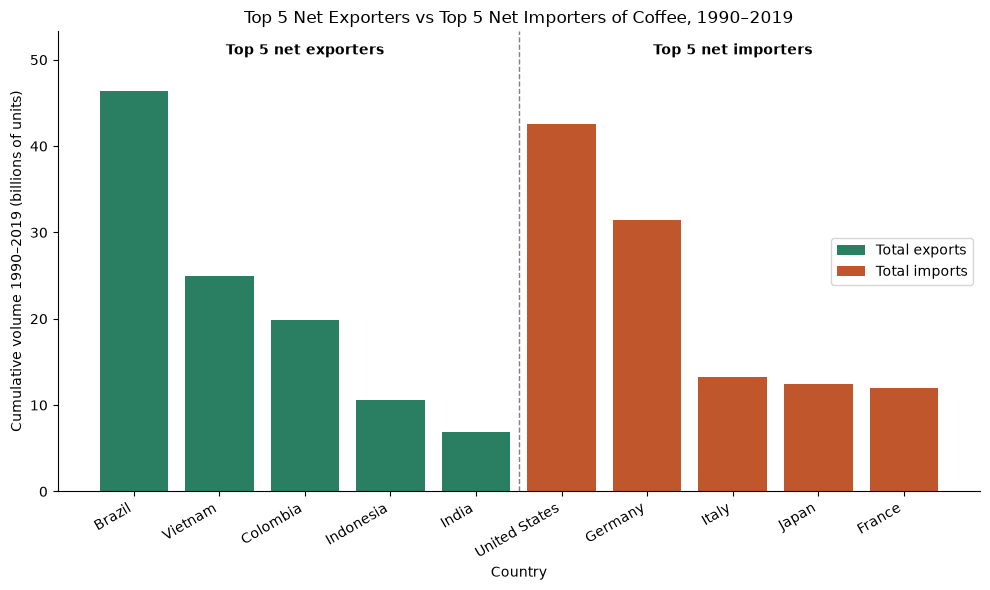

In [19]:
top_exp = master.nlargest(5, "Trade_balance")
top_imp = master.nsmallest(5, "Trade_balance")
sel = pd.concat([top_exp, top_imp])
labels = sel["Country"].tolist()

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(labels, sel["Total_export"] / 1e9, color="#2a7f62", label="Total exports")
ax.bar(labels, sel["Total_import"] / 1e9, bottom=sel["Total_export"] / 1e9,
       color="#c0562b", label="Total imports")

ax.set_ylim(0, (sel["Total_export"] + sel["Total_import"]).max() / 1e9 * 1.15)  # headroom for labels
ax.axvline(4.5, color="gray", ls="--", lw=1)
ax.text(2, ax.get_ylim()[1] * 0.95, "Top 5 net exporters", ha="center", fontweight="bold")
ax.text(7, ax.get_ylim()[1] * 0.95, "Top 5 net importers", ha="center", fontweight="bold")

ax.set_title("Top 5 Net Exporters vs Top 5 Net Importers of Coffee, 1990–2019")
ax.set_xlabel("Country")
ax.set_ylabel("Cumulative volume 1990–2019 (billions of units)")
ax.legend(loc="center right")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

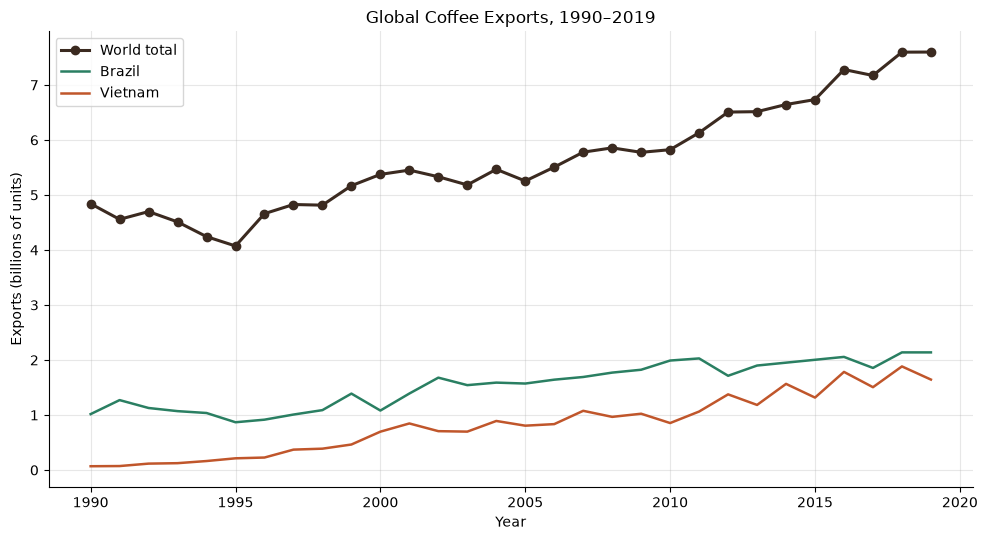

In [20]:
world = exp_c[YEARS].sum()
brazil = exp_c.loc[exp_c["Country"] == "Brazil", YEARS].iloc[0]
vietnam = exp_c.loc[exp_c["Country"] == "Vietnam", YEARS].iloc[0]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(YEARS, world / 1e9, marker="o", lw=2.2, color="#3b2a20", label="World total")
ax.plot(YEARS, brazil / 1e9, lw=1.8, color="#2a7f62", label="Brazil")
ax.plot(YEARS, vietnam / 1e9, lw=1.8, color="#c0562b", label="Vietnam")

ax.set_title("Global Coffee Exports, 1990–2019")
ax.set_xlabel("Year")
ax.set_ylabel("Exports (billions of units)")
ax.grid(alpha=0.3)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

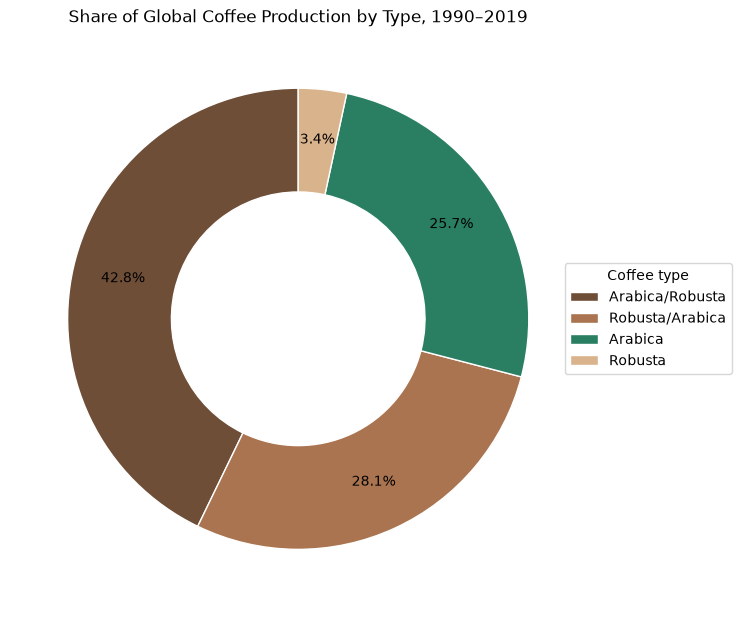

In [21]:
by_type = prod_c.groupby("Coffee type")["Total_production"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 7.5))
wedges, _, _ = ax.pie(by_type, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
                      colors=["#6f4e37", "#a9744f", "#2a7f62", "#d9b38c"],
                      wedgeprops=dict(width=0.45, edgecolor="white"))
ax.legend(wedges, by_type.index, title="Coffee type", loc="center left", bbox_to_anchor=(0.95, 0.5))
ax.set_title("Share of Global Coffee Production by Type, 1990–2019")
plt.tight_layout()
plt.show()

## Part 6 – Executive Summary

**To:** Supply Chain Leadership Team  |  **From:** Data Analytics  |  **Re:** Where coffee is grown, where it is consumed, and where we should secure supply (1990–2019 data)

**Bottom line.** Coffee supply is becoming more concentrated in fewer origins while demand stays concentrated in a few large markets. Our sourcing should deliberately diversify before a single-origin shock forces us to.

**Structural shifts.** Global production grew about 77% (5.6B to 9.9B units) and exports about 57% (4.8B to 7.6B). Brazil produced the largest absolute gain (+1.86B, +113%), but the biggest story is Vietnam: its share of world output rose from 1.4% in 1990 to 18.5% in 2019, overtaking Colombia, whose share fell from 15.4% to 8.5%. Consumption is the mirror image. Production and exports sit in the tropics, while recorded imports are dominated by a few buyers: the United States (24% of imports) and Germany (18%) together take 42%, and the top five importers take 63%. The net-exporter list (Brazil, Vietnam, Colombia, Indonesia, India) shares no members with the net-importer list (United States, Germany, Italy, Japan, France).

**Risks.** Over-reliance on a few producers is the central risk. Brazil, Vietnam and Colombia produced 62% of world coffee in 2019, up from 53% for the top three in 1990, and they supplied 54% of all exports. Brazil alone is 35% of output, so one frost or drought moves the global price. Vietnam's growth is Robusta-led, so a shock there hits blend costs. Our own cleaning also found gaps in the record (unreported years, impossible values for Brazil), so volume figures for smaller origins should be verified before contracts are signed. Note too that the import data covers 35 mostly European countries and omits large consuming markets, so demand growth is understated.

**Recommendations.**
1. **Keep Brazil as the anchor, with a cap.** It has unmatched scale (27% of exports), but we recommend limiting any one origin to roughly a third of our volume.
2. **Make Vietnam and Colombia the second tier under multi-year contracts**: Vietnam for Robusta-led blends and cost stability, Colombia for Arabica quality (12% of exports).
3. **Build a third tier of growing origins** before competitors lock them up: Ethiopia (+152% since 1990), Honduras (+278%) and Indonesia (7% of 2019 output). Each can absorb volume without depending on the top three.
4. **Re-run this analysis annually** with verified data, and track each origin's share of our own purchases against the 2019 benchmark.

In [22]:
# Live demo: messy text numbers -> real numbers (same steps as to_numeric_safe)
messy = pd.Series(["1,234,567 ", " 89,000", "12", "n/a"])
print("Before:", messy.dtype, messy.tolist())

clean = pd.to_numeric(messy.str.replace(",", "", regex=False).str.strip(), errors="coerce")
print("After: ", clean.dtype, clean.tolist())

Before: str ['1,234,567 ', ' 89,000', '12', 'n/a']
After:  float64 [1234567.0, 89000.0, 12.0, nan]


## Global Coffee Company Business Questions

### Question 1 – Largest Coffee Exporter, 1990–1994

Identify the country with the largest total coffee exports from 1990 through 1994. Calculate the cumulative exports for each country, rank the countries from highest to lowest, and identify the largest exporter.

In [23]:
# Question 1: Largest coffee exporter, 1990–1994

question1_years = list(range(1990, 1995))

q1_results = exp_c[["Country"] + question1_years].copy()

q1_results["Total exports (1990–1994)"] = (
    q1_results[question1_years].sum(axis=1)
)

q1_results = (
    q1_results[["Country", "Total exports (1990–1994)"]]
    .sort_values("Total exports (1990–1994)", ascending=False)
    .reset_index(drop=True)
)

display(
    q1_results.head(10).style
    .format({"Total exports (1990–1994)": "{:,.0f}"})
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
    .hide(axis="index")
)

Country,Total exports (1990–1994)
Brazil,"5,521,260,000"
Colombia,"4,106,580,000"
Indonesia,"1,676,700,000"
Ivory Coast,"1,146,660,000"
Mexico,"995,940,000"
Guatemala,"985,500,000"
El Salvador,"709,080,000"
Uganda,"696,420,000"
Costa Rica,"693,960,000"
India,"607,200,000"


### Question 2: Top Five Coffee-Producing Countries, 1999–2004

Identify the five countries with the highest cumulative coffee production from 1999 through 2004. Calculate each country's total production across the six years and rank the countries from highest to lowest.

In [24]:
# Question 2: Top five coffee producers, 1999–2004

question2_years = list(range(1999, 2005))

q2_results = prod_c[["Country"] + question2_years].copy()

q2_results["Total production (1999–2004)"] = (
    q2_results[question2_years].sum(axis=1)
)

q2_results = (
    q2_results.groupby("Country", as_index=False)[
        "Total production (1999–2004)"
    ]
    .sum()
    .sort_values("Total production (1999–2004)", ascending=False)
    .reset_index(drop=True)
)

q2_results.insert(0, "Rank", range(1, len(q2_results) + 1))

display(
    q2_results.head(5).style
    .format({"Total production (1999–2004)": "{:,.0f}"})
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
    .hide(axis="index")
)

Rank,Country,Total production (1999–2004)
1,Brazil,"13,605,540,000"
2,Vietnam,"4,850,760,000"
3,Colombia,"3,970,500,000"
4,Indonesia,"2,462,880,000"
5,India,"1,715,040,000"


### Question 3: Second-Highest Producing Country by Coffee Type, 1990–1994

For each coffee type, identify the country or countries with the second-highest cumulative production from 1990 through 1994. If countries tie for second place, include all tied countries.

In [25]:
# Question 3: Second-highest producer by coffee type, 1990–1994

question3_years = list(range(1990, 1995))

q3_results = prod_c[
    ["Country", "Coffee type"] + question3_years
].copy()

q3_results["Total production (1990–1994)"] = (
    q3_results[question3_years].sum(axis=1)
)

q3_totals = (
    q3_results.groupby(
        ["Coffee type", "Country"], as_index=False
    )["Total production (1990–1994)"]
    .sum()
)

q3_totals["Rank"] = (
    q3_totals.groupby("Coffee type")[
        "Total production (1990–1994)"
    ]
    .rank(method="min", ascending=False)
)

q3_second = (
    q3_totals[q3_totals["Rank"] == 2]
    .sort_values(["Coffee type", "Country"])
    .reset_index(drop=True)
)

display(
    q3_second[
        ["Coffee type", "Country", "Total production (1990–1994)", "Rank"]
    ].style
    .format({
        "Total production (1990–1994)": "{:,.0f}",
        "Rank": "{:.0f}"
    })
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
    .hide(axis="index")
)

Coffee type,Country,Total production (1990–1994),Rank
Arabica,Ethiopia,"803,340,000",2
Arabica/Robusta,Mexico,"1,319,040,000",2
Robusta,Madagascar,"247,200,000",2
Robusta/Arabica,India,"911,220,000",2


### Question 4: Global Coffee Trade Footprint

Across the full dataset timespan, calculate each country's total recorded exports and imports. Combine these totals to identify the five countries with the largest overall trade volume, ranked from highest to lowest.

In [26]:
# Question 4: Top five countries by total exports and imports

export_years = [
    col for col in exp_c.columns
    if isinstance(col, int)
]

import_years = [
    col for col in imp_c.columns
    if isinstance(col, int)
]

# Calculate total exports by country
country_exports = exp_c[["Country"] + export_years].copy()

country_exports["Total exports"] = (
    country_exports[export_years].sum(axis=1)
)

country_exports = (
    country_exports[["Country", "Total exports"]]
    .groupby("Country", as_index=False)["Total exports"]
    .sum()
)

# Calculate total imports by country
country_imports = imp_c[["Country"] + import_years].copy()

country_imports["Total imports"] = (
    country_imports[import_years].sum(axis=1)
)

country_imports = (
    country_imports[["Country", "Total imports"]]
    .groupby("Country", as_index=False)["Total imports"]
    .sum()
)

# Combine exports and imports
q4_results = country_exports.merge(
    country_imports,
    on="Country",
    how="outer"
).fillna(0)

q4_results["Total trade"] = (
    q4_results["Total exports"] + q4_results["Total imports"]
)

# Rank countries by total trade
q4_results = (
    q4_results.sort_values("Total trade", ascending=False)
    .reset_index(drop=True)
)

q4_results.insert(0, "Rank", range(1, len(q4_results) + 1))

# Display the top five with left-aligned headers and values
display(
    q4_results.head(5).style
    .format({
        "Total exports": "{:,.0f}",
        "Total imports": "{:,.0f}",
        "Total trade": "{:,.0f}"
    })
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
    .hide(axis="index")
)

Rank,Country,Total exports,Total imports,Total trade
1,Brazil,"46,343,580,000",0,"46,343,580,000"
2,United States,0,"42,507,660,000","42,507,660,000"
3,Germany,0,"31,481,400,000","31,481,400,000"
4,Vietnam,"24,924,480,000",0,"24,924,480,000"
5,Colombia,"19,878,480,000",0,"19,878,480,000"


**Interpretation:** The export and import datasets contain different sets of countries. A value of 0 therefore means that no total was recorded for that country in the corresponding dataset; it does not establish that the country had no real-world exports or imports. The combined ranking compares recorded export and import volumes across both datasets.

### Question 5: Coffee Sourcing Traceability

Can these datasets identify which exporting country supplied coffee to which importing country?

The datasets contain country-level export and import totals by year, but they do not provide bilateral trade records linking a specific exporter to a specific importer. Therefore, they cannot establish which country supplied coffee to another country.

To support sourcing traceability, the company would need additional data, such as exporter–importer transaction records, supplier information, shipment records, or bills of lading.